In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# Primeros pasos

Un recorrido de diez minutos por `dane-data` con los microdatos reales de la GEIH y la EAM. Todas las
salidas de esta página salieron de ejecutar el código.

Si todavía no tiene los datos, instale la librería ({doc}`instalacion`) y descargue lo que vaya a usar: la
primera descarga de un año de la GEIH tarda unos minutos.

In [2]:
import dane_data as dd

# dd.geih.download(2025)               # un año de la GEIH (unos 500 MB)
# dd.eam.download(range(2012, 2025))   # la EAM desde 2012
dd.__version__

'0.3.1'

## 1. Qué hay descargado

{dd}`geih.available()` revisa las carpetas y dice qué meses están completos.

In [3]:
dd.geih.available().groupby("anio")["completo"].sum().tail()

anio
2022    12
2023    12
2024    12
2025    12
2026     8
Name: completo, dtype: int64

## 2. Cargar un año

{dd}`geih.load()` une los módulos de cada mes y devuelve una fila por persona. Las variables en minúscula
son las **armonizadas** por `dane-data`, iguales en todos los años; las de MAYÚSCULA, las originales del
DANE.

In [4]:
df = dd.geih.load(2025)
df.shape

(817550, 69)

In [5]:
df[["anio", "mes", "fex", "sexo", "edad", "departamento", "condicion", "formal", "ingreso_laboral"]].head()

,anio,mes,fex,sexo,edad,departamento,condicion,formal,ingreso_laboral
0,2025,1,2184.752283,Mujer,54.0,Bolívar,Ocupado,0,1040000.0
1,2025,1,1208.490211,Mujer,79.0,Bolívar,Inactivo,<NA>,NaN
2,2025,1,1208.490211,Hombre,60.0,Bolívar,Ocupado,0,700000.0
3,2025,1,1208.490211,Hombre,59.0,Bolívar,Ocupado,0,1450000.0
4,2025,1,2104.113905,Mujer,80.0,Bolívar,Inactivo,<NA>,NaN


Cada persona representa a `fex` personas de la población: es el {doc}`factor de expansión
<guia/ponderacion>`. Como es mensual, con doce meses la población es la suma de `fex` dividida por 12.
`dane-data` hace esa cuenta sola en todas sus funciones.

## 3. Indicadores del mercado laboral

{dd}`geih.indicadores()` calcula los indicadores que publica el DANE: niveles en personas (promedio
mensual del año) y tasas en porcentaje.

In [6]:
dd.geih.indicadores(df)[["anio", "pet", "fuerza_trabajo", "ocupados", "desocupados", "tgp", "to", "td",
                          "tasa_informalidad"]].round(1)

,anio,pet,fuerza_trabajo,ocupados,desocupados,tgp,to,td,tasa_informalidad
0,2025,40674210.4,26153379.4,23827433.9,2325945.5,64.3,58.6,8.9,55.7


Con `por` se desagrega por cualquier variable:

In [7]:
dd.geih.indicadores(df, por="sexo")[["sexo", "tgp", "to", "td", "tasa_informalidad", "ingreso_medio"]].round(1)

,sexo,tgp,to,td,tasa_informalidad,ingreso_medio
0,Hombre,76.8,71.4,7.0,58.0,1965065.1
1,Mujer,52.8,46.7,11.4,52.6,1821904.8


## 4. Tablas ponderadas

{dd}`tabla()` expande cualquier variable: totales, porcentajes, medias o medianas por grupo.

In [8]:
ocupados = df[df.ocupado == 1]
dd.tabla(ocupados, por="nivel_educativo", variable="ingreso_laboral", estadistico="media").round(0)

,nivel_educativo,media,n_muestra
0,Ninguno,727452.0,8898
1,Primaria,1020185.0,59694
2,Secundaria,1116744.0,36876
3,Media,1400095.0,120786
4,Superior,3216506.0,123576


In [9]:
dd.tabla(ocupados, por="posicion_ocupacional", estadistico="porcentaje").round(1)

,posicion_ocupacional,total,n_muestra,porcentaje
0,Empleado particular,10567954.3,150485,44.4
1,Empleado del gobierno,873386.4,18499,3.7
2,Empleado doméstico,716097.6,12040,3.0
3,Cuenta propia,9840608.9,154458,41.3
4,Patrón o empleador,581815.2,8134,2.4
5,Familiar sin remuneración,432386.7,5830,1.8
6,Jornalero o peón,806040.6,8429,3.4
7,Otro,9144.3,154,0.0


## 5. Una serie larga

Juntar veinte años de microdatos no cabe en la memoria de un portátil. {dd}`geih.serie_indicadores()` da el
mismo resultado que `indicadores` pero calcula un año a la vez y guarda cada año en disco: la primera vez
tarda alrededor de un minuto; después es instantáneo.

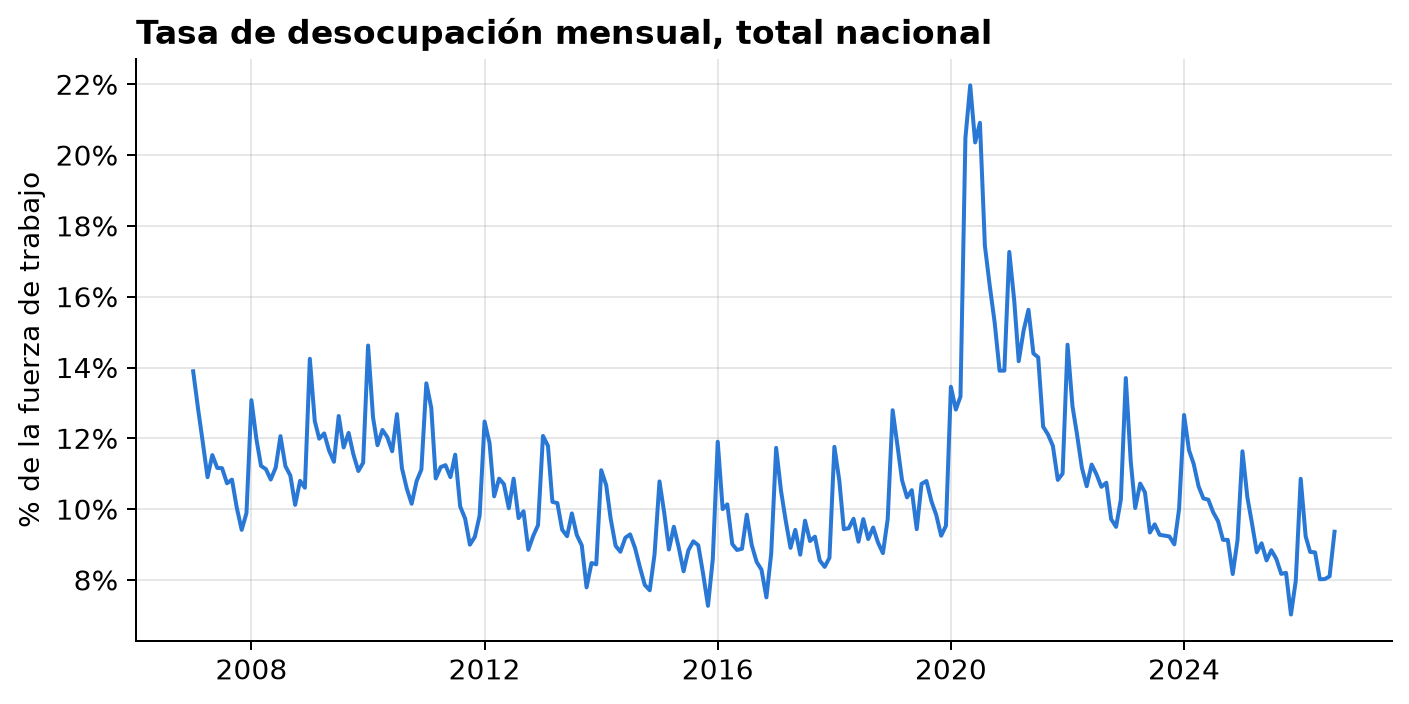

In [10]:
serie = dd.geih.serie_indicadores(range(2007, 2027), anual=False)
serie["fecha"] = pd.to_datetime(serie[["anio", "mes"]].rename(columns={"anio": "year", "mes": "month"}).assign(day=1))

fig, ax = plt.subplots()
ax.plot(serie["fecha"], serie["td"], lw=1.6)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Tasa de desocupación mensual, total nacional")
ax.set_ylabel("% de la fuerza de trabajo");

Los años 2007–2019 y 2021 tienen el marco del censo 2005, y 2020 y 2022 en adelante el del CNPV 2018: los
niveles de un marco y otro no son del todo comparables (vea {doc}`guia/encuestas`). El ejemplo
{doc}`ejemplos/desempleo` lo trata en detalle.

## 6. La industria: EAM

{dd}`eam.load()` carga la Encuesta Anual Manufacturera, un establecimiento por fila, y {dd}`eam.resumen()`
calcula los agregados. Los montos están en miles de pesos corrientes.

In [11]:
eam = dd.eam.load(range(2012, 2025))
res = dd.eam.resumen(eam, por="anio")
res[["anio", "establecimientos", "personal_total", "valor_agregado", "productividad_laboral",
     "participacion_laboral"]].tail().round(1)

,anio,establecimientos,personal_total,valor_agregado,productividad_laboral,participacion_laboral
8,2020,7343,660404.0,9.233033e+10,139808.9,22.7
9,2021,7138,681246.0,1.169685e+11,171697.9,19.6
10,2022,6775,710060.0,1.491993e+11,210122.1,16.7
11,2023,6714,718730.0,1.488453e+11,207094.9,19.2
12,2024,6583,730236.0,1.482664e+11,203039.1,21.7


## Siguientes pasos

* La {doc}`guia/index` explica las variables, la ponderación y cada indicador en detalle.
* Los {doc}`ejemplos/index` muestran análisis completos: brechas de género, informalidad, salario mínimo,
  desempleo juvenil, industria.
* La {doc}`api/index` documenta cada función.
* Si prefiere no escribir código, `dane-data app` abre la {doc}`aplicación <guia/app>`.